[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Datetime'>

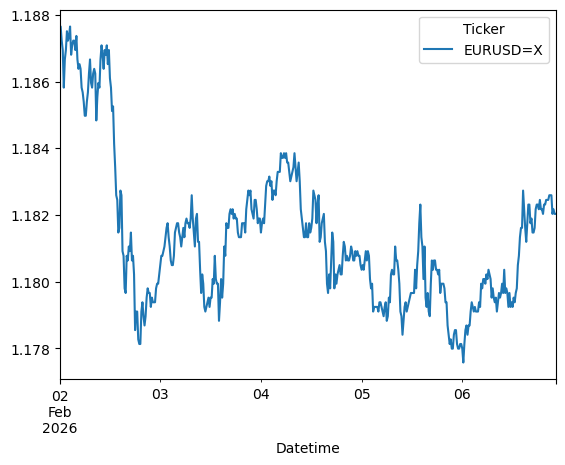

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from arch.unitroot import ADF
import pandas as pd

veri = yf.download("EURUSD=X", period="5d", interval="15m")
kapanış_verisi = veri["Close"]
kapanış_verisi.plot()



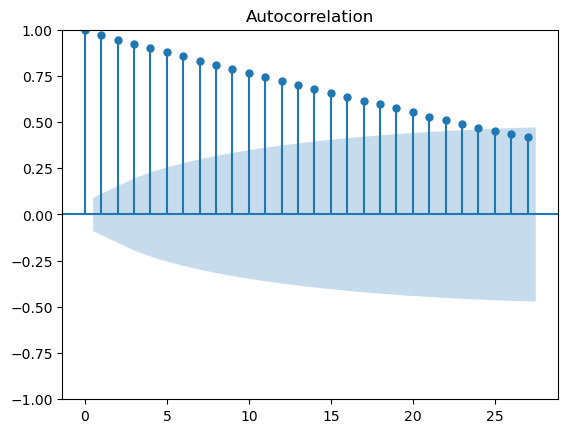

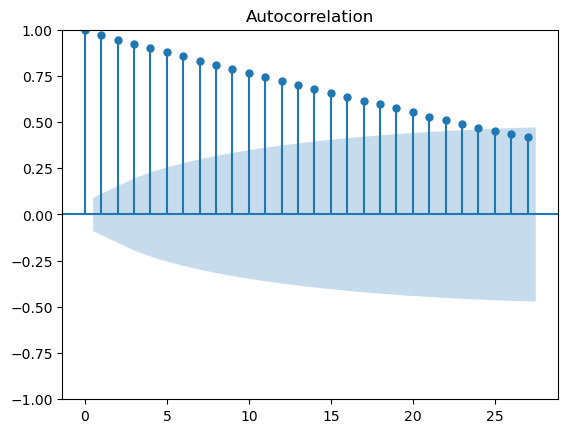

In [2]:
plot_acf(kapanış_verisi)

In [3]:
ADF(kapanış_verisi)

Test Statistic,-3.070
P-value,0.029
Lags,0


<Axes: xlabel='Datetime'>

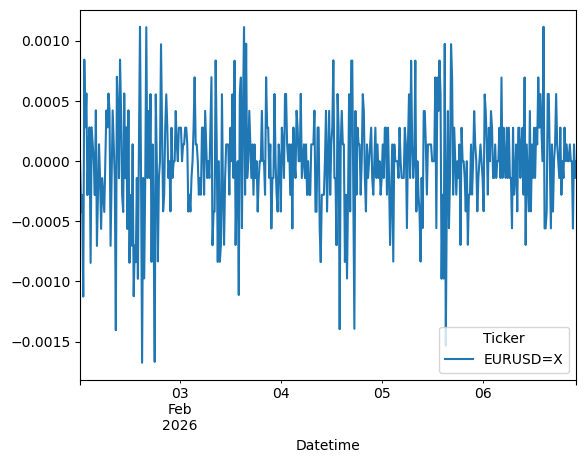

In [4]:
getiri = kapanış_verisi.diff().dropna()
getiri.plot()


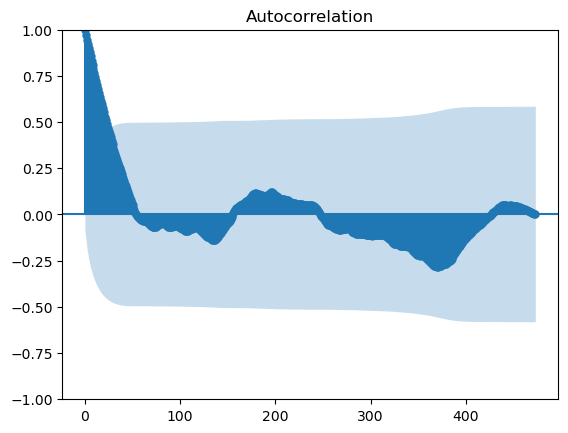

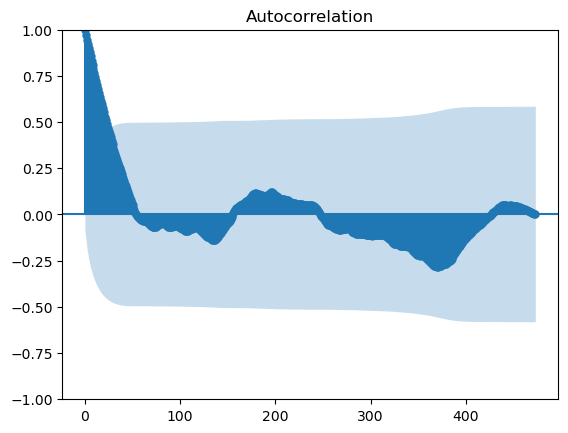

In [5]:
plot_acf(kapanış_verisi, lags=len(getiri))

In [6]:
hisseler = ["TUPRS.IS", "ASELS.IS"]
veri = yf.download(hisseler, period="2y", interval="1d")
kapanış_verileri = veri["Close"]
kapanış_verileri

[*********************100%***********************]  2 of 2 completed


Ticker,ASELS.IS,TUPRS.IS
Date,,
2024-02-06,52.148163,122.863998
2024-02-07,51.101212,122.704964
2024-02-08,51.200920,125.488274
2024-02-09,51.948746,125.408752
2024-02-12,53.294827,129.464462
...,...,...
2026-02-02,299.500000,229.600006
2026-02-03,296.750000,234.000000
2026-02-04,302.500000,229.199997


In [7]:
asels = kapanış_verileri["ASELS.IS"]
asels


Date
2024-02-06     52.148163
2024-02-07     51.101212
2024-02-08     51.200920
2024-02-09     51.948746
2024-02-12     53.294827
                 ...    
2026-02-02    299.500000
2026-02-03    296.750000
2026-02-04    302.500000
2026-02-05    285.000000
2026-02-06    288.000000
Name: ASELS.IS, Length: 501, dtype: float64

In [8]:
type(asels)

pandas.core.series.Series

In [9]:
type(asels)

pandas.core.series.Series

In [10]:
pip install evds --upgrade

Note: you may need to restart the kernel to use updated packages.


In [11]:
import evds
with open("C:/Users/merty/Desktop/evds.txt") as file:
    api = file.read()

In [12]:
e = evds.evdsAPI(api)

In [13]:
kat = e.main_categories

In [14]:
alt = e.get_sub_categories(36)

In [15]:
seri = e.get_series("bie_sgegi")

In [16]:
veri = e.get_data(["TP.SGEGI.K1"], startdate="07-02-2016", enddate="07-02-2026")

In [17]:
veri.set_index("Tarih")

,TP_SGEGI_K1
Tarih,
2016-2,1143.0
2016-3,1335.0
2016-4,1336.0
2016-5,1819.0
2016-6,1774.0
...,...
2025-5,5109.0
2025-6,5953.0
2025-7,7008.0


In [54]:
veri.rename(columns={
    "TP_SGEGI_K1" : "TurizmGelir"
}, inplace=True)

tarih = pd.date_range("2016-2", periods=len(veri), freq="ME") #indexe koyulacak tarihi ölçeklendirmek için

veri.set_index(tarih, inplace=True)

<Axes: >

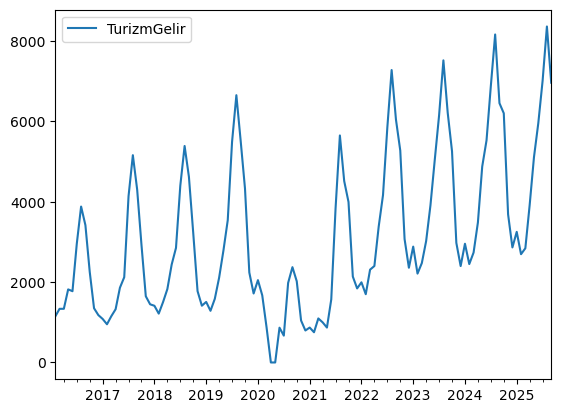

In [55]:
veri.plot()